# 01 - Exploration et audit qualité des données

**Projet :** EnergyForecast, prévision de la production solaire photovoltaïque.

**Objectif de ce notebook :** comprendre le dataset et mesurer sa qualité *avant* de le nettoyer.
Ici on ne modifie rien, on diagnostique.

Données : https://zenodo.org/records/7330512 (à placer dans `data/raw/PV_firstRealease.xlsx`).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/PV_firstRealease.xlsx"


## 1. Chargement

Le fichier Excel contient 3 feuilles (une par année). Le chargement peut prendre une minute.

In [5]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None)   # dict {nom_feuille: DataFrame}
for name, df in sheets.items():
    print(name, df.shape)


Year 1 (105120, 14)
Year 2 (105120, 14)
Year 3 (105120, 14)


## 2. Aperçu général

In [14]:
df1 = sheets["Year 1"]
df1.head(10)

,Hour,Starting minute (inclussive),Ending minute (exclussive),Generated power,TemperatureC,DewpointC,PressurehPa,WindDirectionDegrees,WindSpeedKMH,WindSpeedGustKMH,Humidity,HourlyPrecipMM,dailyrainMM,SolarRadiationWatts_m2
0,0,0,5,0,0,0,0,0,0,0,0,0,0,0
1,0,5,10,0,0,0,0,0,0,0,0,0,0,0
2,0,10,15,0,11,8,1021,114,1,17,83,0,0,0
3,0,15,20,0,11,8,1021,134,12,17,83,0,0,0
4,0,20,25,0,11,8,1021,128,8,17,83,0,0,0
5,0,25,30,0,11,8,1021,123,6,17,83,0,0,0
6,0,30,35,0,11,8,1021,143,0,20,83,0,0,0
7,0,35,40,0,11,8,1021,128,0,20,83,0,0,0
8,0,40,45,0,11,8,1021,129,4,17,83,0,0,0
9,0,45,50,0,11,8,1021,136,4,14,83,0,0,0


In [15]:
df1.dtypes

Hour                            int64
Starting minute (inclussive)    int64
Ending minute (exclussive)      int64
Generated power                 int64
TemperatureC                    int64
DewpointC                       int64
PressurehPa                     int64
WindDirectionDegrees            int64
WindSpeedKMH                    int64
WindSpeedGustKMH                int64
Humidity                        int64
HourlyPrecipMM                  int64
dailyrainMM                     int64
SolarRadiationWatts_m2          int64
dtype: object

## 3. Valeurs manquantes et doublons

Attention : `isna()` ne détecte que les cellules vides. Ici les valeurs manquantes sont souvent
**encodées autrement** (0, -999, 65535), on les cherche plus bas.

In [6]:
rows = []
for name, df in sheets.items():
    rows.append({"feuille": name, "lignes": len(df),
                 "NaN": int(df.isna().sum().sum()),
                 "doublons": int(df.duplicated().sum())})
pd.DataFrame(rows)

,feuille,lignes,NaN,doublons
0,Year 1,105120,0,4733
1,Year 2,105120,0,3380
2,Year 3,105120,0,7302


## 4. Statistiques descriptives

On regarde les `min` et `max` : plusieurs sont physiquement impossibles.

In [7]:
for name, df in sheets.items():
    print("=====", name)
    display(df.describe().T[["min", "max", "mean", "std"]])

===== Year 1


,min,max,mean,std
Hour,0.0,23.0,11.500000,6.922219
Starting minute (inclussive),0.0,55.0,27.500000,17.260345
Ending minute (exclussive),5.0,60.0,32.500000,17.260345
Generated power,0.0,2693902.0,778.669254,10414.909797
TemperatureC,-17.0,39.0,14.229024,6.509170
DewpointC,-17.0,20.0,10.467380,4.885909
PressurehPa,0.0,3386.0,943.898202,270.708983
WindDirectionDegrees,0.0,355.0,204.651950,110.294995
WindSpeedKMH,0.0,69.0,2.760112,4.775849
WindSpeedGustKMH,0.0,1608.0,9.187253,29.241273


===== Year 2


,min,max,mean,std
Hour,0.0,23.0,11.500000,6.922219
Starting minute (inclussive),0.0,55.0,27.500000,17.260345
Ending minute (exclussive),5.0,60.0,32.500000,17.260345
Generated power,0.0,6057.0,774.073164,1337.855385
TemperatureC,-572.0,37.0,14.495786,6.857498
DewpointC,-73.0,21.0,9.987481,5.319247
PressurehPa,-3386.0,1038.0,949.559798,256.432197
WindDirectionDegrees,-999.0,355.0,204.821223,112.403811
WindSpeedKMH,-1607.0,51.0,2.654110,8.533259
WindSpeedGustKMH,-1607.0,75.0,7.684437,11.610868


===== Year 3


,min,max,mean,std
Hour,0.0,23.0,11.500000,6.922219
Starting minute (inclussive),0.0,55.0,27.500000,17.260345
Ending minute (exclussive),5.0,60.0,32.500000,17.260345
Generated power,0.0,6057.0,732.816705,1258.754727
TemperatureC,-17.0,77.0,15.307106,11.991067
DewpointC,-17.0,64.0,11.741201,10.819122
PressurehPa,0.0,1035.0,835.576636,386.557052
WindDirectionDegrees,0.0,360.0,190.799382,118.673864
WindSpeedKMH,0.0,51.0,4.827540,5.522494
WindSpeedGustKMH,-1607.0,70.0,-2.727673,145.410194


## 5. Codes d'erreur capteur (valeurs sentinelles)

`-999` et `65535` ne sont pas de vraies mesures, ce sont des codes d'erreur.

In [16]:
# Colonnes où une valeur négative est physiquement impossible
NON_NEGATIVE = ["Generated power", "PressurehPa", "WindDirectionDegrees",
                "WindSpeedKMH", "WindSpeedGustKMH", "Humidity",
                "HourlyPrecipMM", "dailyrainMM", "SolarRadiationWatts_m2"]

rows = []
for name, df in sheets.items():
    rows.append({"feuille": name,
                 "valeurs -999": int((df == -999).sum().sum()),
                 "valeurs 65535": int((df == 65535).sum().sum()),
                 "négatives impossibles": int((df[NON_NEGATIVE] < 0).sum().sum())})
pd.DataFrame(rows)

,feuille,valeurs -999,valeurs 65535,négatives impossibles
0,Year 1,38,0,75
1,Year 2,4,0,71
2,Year 3,0,147,853


## 6. Valeurs hors plage physique

On définit des bornes réalistes pour chaque variable (climat tempéré) et on compte
les valeurs qui sortent de ces bornes.

In [9]:
BOUNDS = {
    "TemperatureC": (-30, 50),
    "DewpointC": (-30, 35),
    "PressurehPa": (900, 1080),
    "WindDirectionDegrees": (0, 360),
    "WindSpeedKMH": (0, 150),
    "WindSpeedGustKMH": (0, 200),
    "Humidity": (0, 100),
    "HourlyPrecipMM": (0, 100),
    "dailyrainMM": (0, 300),
    "SolarRadiationWatts_m2": (0, 1400),
}

rows = []
for name, df in sheets.items():
    for col, (lo, hi) in BOUNDS.items():
        bad = int(((df[col] < lo) | (df[col] > hi)).sum())
        rows.append({"feuille": name, "colonne": col, "hors_plage": bad,
                     "pourcentage": round(100 * bad / len(df), 2)})

report = pd.DataFrame(rows).pivot(index="colonne", columns="feuille", values="hors_plage")
report

feuille,Year 1,Year 2,Year 3
colonne,,,
DewpointC,0,2,5416
HourlyPrecipMM,77,7,19
Humidity,43,2,61
PressurehPa,7808,7106,18835
SolarRadiationWatts_m2,36,0,97
TemperatureC,0,2,4646
WindDirectionDegrees,0,2,0
WindSpeedGustKMH,32,2,853
WindSpeedKMH,0,2,0


## 7. Zéros "fantômes" : données météo manquantes encodées en 0

Une pression de 0 hPa ou une humidité de 0 % simultanée à une température de 0 °C n'a pas de sens :
c'est un capteur éteint. Pour la pluie, le vent, la radiation ou la puissance, 0 est légitime.

In [10]:
MET = ["TemperatureC", "PressurehPa", "Humidity"]

rows = []
for name, df in sheets.items():
    z = (df[MET] == 0).all(axis=1)
    rows.append({"feuille": name,
                 "lignes_meteo_a_zero": int(z.sum()),
                 "pourcentage": round(100 * z.mean(), 2)})
pd.DataFrame(rows)

,feuille,lignes_meteo_a_zero,pourcentage
0,Year 1,7733,7.36
1,Year 2,7104,6.76
2,Year 3,13419,12.77


### Longueur des séquences de zéros

Des trous courts (moins d'1 h) sont interpolables, les longs non.

In [11]:
def zero_runs(df):
    z = (df[MET] == 0).all(axis=1).astype(int)
    groups = (z != z.shift()).cumsum()
    runs = z.groupby(groups).agg(["first", "size"])
    return runs[runs["first"] == 1]["size"]

rows = []
for name, df in sheets.items():
    r = zero_runs(df)
    rows.append({"feuille": name, "nb_sequences": len(r),
                 "plus_longue (x5 min)": int(r.max()),
                 "sequences >= 1h": int((r >= 12).sum())})
pd.DataFrame(rows)

,feuille,nb_sequences,plus_longue (x5 min),sequences >= 1h
0,Year 1,4207,1153,13
1,Year 2,2025,865,18
2,Year 3,1294,3782,60


## 8. Cohérence physique : puissance vs radiation solaire

Sans soleil, un panneau ne produit pas. Une puissance > 0 avec radiation = 0 est suspecte
(décalage temporel entre capteurs, ou erreur de mesure).

In [12]:
rows = []
for name, df in sheets.items():
    p = df["Generated power"]
    rows.append({"feuille": name,
                 "puissance>0 et radiation=0": int(((p > 0) & (df["SolarRadiationWatts_m2"] == 0)).sum()),
                 "puissance > 10000": int((p > 10000).sum()),
                 "puissance max": int(p.max())})
pd.DataFrame(rows)

,feuille,puissance>0 et radiation=0,puissance > 10000,puissance max
0,Year 1,10183,4,2693902
1,Year 2,5820,0,6057
2,Year 3,7102,0,6057


## 9. Visualisation : puissance moyenne par heure de la journée

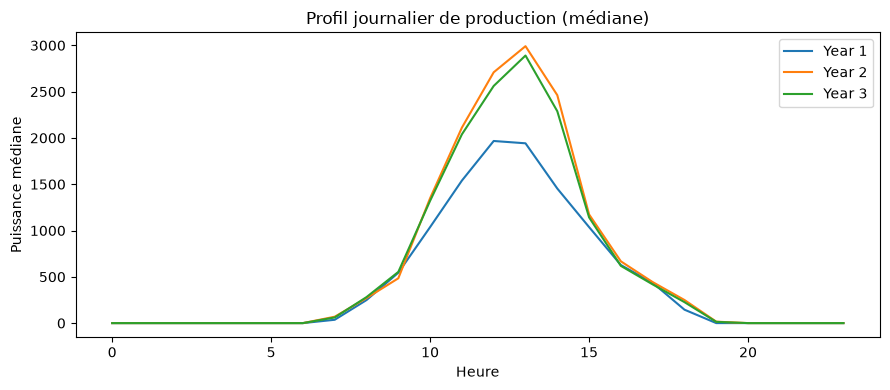

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, df in sheets.items():
    df.groupby("Hour")["Generated power"].median().plot(ax=ax, label=name)
ax.set_xlabel("Heure")
ax.set_ylabel("Puissance médiane")
ax.set_title("Profil journalier de production (médiane)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/profil_journalier.png", dpi=150)
plt.show()

## 10. Conclusions de l'audit

- Aucune cellule vide, mais de nombreuses valeurs manquantes encodées en 0, -999 ou 65535.
- Des valeurs physiquement impossibles (pression, température, vent, humidité).
- Quelques pics extrêmes sur la puissance et la radiation.
- Des séquences de capteur coupé pouvant durer plusieurs jours.
- Pas de colonne date : seulement l'heure et la minute dans la journée.

**Prochaine étape :** `02_nettoyage.ipynb` (remplacer les codes d'erreur par NaN, traiter les zéros fantômes,
borner les valeurs aberrantes, interpoler les trous courts).